# Bayesian search backtest

Uses Optuna to pick each next config based on the ones already scored, so it can explore wider ranges than a grid with the same budget. Same models, dates, and metrics as the grid search notebook.

## Setup

All imports live here. The notebook moves to the repo root so it uses the same config and MLflow store as `natgas tune`.

In [1]:
import logging
import os
import warnings
from pathlib import Path

os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"
os.environ["HF_HUB_DISABLE_TELEMETRY"] = "1"
os.environ["TRANSFORMERS_NO_ADVISORY_WARNINGS"] = "1"
os.environ["HF_HUB_DISABLE_EXPERIMENTAL_WARNING"] = "1"
os.environ["TOKENIZERS_PARALLELISM"] = "false"

import matplotlib.pyplot as plt
import mlflow
import pandas as pd

from natgas.config import load_settings
from natgas.forecasting.backtesting import Backtester
from natgas.forecasting.data import ForecastDataProvider
from natgas.forecasting.models.chronos.ChronosModel import ChronosModel
from natgas.forecasting.models.chronos.ChronosModelConfig import ChronosModelConfig
from natgas.forecasting.optimization import BayesianOptimizer
from natgas.forecasting.tuning import ModelPublisher, TuningConfig

# Run from the repo root so config files, mlflow.db, and mlruns/ line up
if Path.cwd().name == "experiments":
    os.chdir(Path.cwd().parent)

warnings.filterwarnings("ignore")
logging.getLogger().setLevel(logging.WARNING)
for name in ["natgas", "mlflow", "greykite", "optuna", "huggingface_hub", "transformers", "torch"]:
    logging.getLogger(name).setLevel(logging.ERROR)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)

# Download Chronos-2 once, then stay offline so worker processes do not
# retry Hugging Face and print timeout warnings.
ChronosModel.pipeline_for(ChronosModelConfig().model_id, "cpu")
os.environ["HF_HUB_OFFLINE"] = "1"

# Greykite switches matplotlib to a file backend, so turn inline charts back on
%matplotlib inline

## Data

`ForecastDataProvider` is the only way models get data. Every as-of date gets training data up to that date and the next 30 trading days to score against. The dates are the same in both notebooks, so the results are comparable.

In [2]:
tuning = TuningConfig.from_yaml("config/tuning.yaml")
settings = load_settings()
provider = ForecastDataProvider.from_settings(settings, tuning.horizon_days, tuning.target_column)
as_of_dates = provider.backtest_dates(tuning.backtest_start, tuning.backtest_end, tuning.step_days)

first, last = provider.first_date.date(), provider.last_date.date()
print(f"prices: {first} to {last}, {len(provider.target)} trading days")
print(f"features: {provider.feature_columns}")
print(
    f"{len(as_of_dates)} as-of dates from {as_of_dates[0].date()} to {as_of_dates[-1].date()}, "
    f"{tuning.horizon_days} trading days ahead each"
)

prices: 2015-01-02 to 2026-11-18, 2989 trading days
features: ['hdd', 'cdd', 'christmas_day', 'christmas_day_pre_1', 'christmas_day_pre_2', 'christmas_day_pre_3', 'christmas_day_pre_4', 'christmas_day_post_1', 'christmas_day_post_2', 'christmas_day_post_3', 'christmas_day_post_4', 'columbus_day', 'columbus_day_pre_1', 'columbus_day_pre_2', 'columbus_day_pre_3', 'columbus_day_pre_4', 'columbus_day_post_1', 'columbus_day_post_2', 'columbus_day_post_3', 'columbus_day_post_4', 'independence_day', 'independence_day_pre_1', 'independence_day_pre_2', 'independence_day_pre_3', 'independence_day_pre_4', 'independence_day_post_1', 'independence_day_post_2', 'independence_day_post_3', 'independence_day_post_4', 'juneteenth_national_independence_day', 'juneteenth_national_independence_day_pre_1', 'juneteenth_national_independence_day_pre_2', 'juneteenth_national_independence_day_pre_3', 'juneteenth_national_independence_day_pre_4', 'juneteenth_national_independence_day_post_1', 'juneteenth_nationa

## Search space

Each model's options come from `config/tuning.yaml` (the `search_space` key) and map into that model's config class.

In [3]:
spaces = {name: settings.get("search_space") for name, settings in tuning.model_settings.items()}
pd.Series(spaces, name="search_space").to_frame()

,search_space
naive,None
gradient_boosting,"{'n_lags': {'low': 3, 'high': 20}, 'learning_rate': {'low': 0.01, 'high': 0.3, 'log': True}, 'max_depth': {'low': 2,..."
greykite,"{'history_years': {'low': 2.0, 'high': 8.0}, 'autoregression_lags': {'low': 0, 'high': 5}, 'use_holidays': [True, Fa..."
chronos,"{'context_length': {'low': 64, 'high': 2048, 'step': 64}, 'use_weather': [True, False], 'use_yearly': [True, False],..."


## Run the backtests

Each config is backtested on every as-of date and logged as a nested MLflow run.

In [4]:
backtester = Backtester(provider, as_of_dates, n_jobs=tuning.n_jobs)
optimizer = BayesianOptimizer(
    backtester, tuning.selection_metric, n_trials=tuning.n_trials, seed=tuning.seed
)

mlflow.set_tracking_uri(tuning.tracking_uri)
mlflow.set_experiment("natgas-bayesian-search")
with mlflow.start_run(run_name="bayesian-search-notebook") as search_run:
    mlflow.set_tag("method", "bayesian")
    mlflow.log_params(
        {
            "backtest_count": len(as_of_dates),
            "horizon_days": tuning.horizon_days,
            "n_trials": tuning.n_trials,
        }
    )
    summary = optimizer.run(tuning.model_settings)

print(f"{len(summary)} configs backtested, {len(optimizer.failed)} failed")

19 configs backtested, 0 failed


## Results

Lower is better. `skill_vs_naive` above zero means the config beats repeating the last price.

In [5]:
scores = ["mae", "rmse", "mape", "wape", "bias", "skill_vs_naive"]
columns = ["model_name", "config", *scores, "seconds"]
summary[columns].round(4)

,model_name,config,mae,rmse,mape,wape,bias,skill_vs_naive,seconds
0,chronos,"{""context_length"": 640, ""device"": ""cpu"", ""model_id"": ""amazon/chronos-2"", ""use_weather"": true, ""use_weekend"": false, ...",0.5174,0.7905,13.1155,13.6001,-0.0310,0.0163,8.6
1,chronos,"{""context_length"": 1280, ""device"": ""cpu"", ""model_id"": ""amazon/chronos-2"", ""use_weather"": true, ""use_weekend"": false,...",0.5221,0.7979,13.1143,13.7240,-0.0480,0.0073,452.8
2,chronos,"{""context_length"": 960, ""device"": ""cpu"", ""model_id"": ""amazon/chronos-2"", ""use_weather"": true, ""use_weekend"": true, ""...",0.5229,0.7998,13.2389,13.7451,-0.0325,0.0058,12.4
3,naive,{},0.5259,0.8107,13.4958,13.8249,0.0037,0.0000,6.7
4,chronos,"{""context_length"": 768, ""device"": ""cpu"", ""model_id"": ""amazon/chronos-2"", ""use_weather"": true, ""use_weekend"": false, ...",0.5263,0.8148,13.3072,13.8341,-0.0029,-0.0007,32.4
5,gradient_boosting,"{""l2_regularization"": 0.0, ""learning_rate"": 0.01351182947645082, ""max_depth"": 2, ""max_iter"": 200, ""min_samples_leaf""...",0.5269,0.8133,13.4339,13.8492,-0.0036,-0.0018,4.4
6,gradient_boosting,"{""l2_regularization"": 0.0, ""learning_rate"": 0.03476649150592621, ""max_depth"": 4, ""max_iter"": 200, ""min_samples_leaf""...",0.5366,0.8209,13.7839,14.1062,0.0551,-0.0203,5.2
7,gradient_boosting,"{""l2_regularization"": 0.0, ""learning_rate"": 0.09519754482692679, ""max_depth"": 3, ""max_iter"": 200, ""min_samples_leaf""...",0.5369,0.8302,13.9388,14.1130,0.0630,-0.0208,4.0
8,chronos,"{""context_length"": 256, ""device"": ""cpu"", ""model_id"": ""amazon/chronos-2"", ""use_weather"": true, ""use_weekend"": false, ...",0.5397,0.8213,13.7155,14.1856,-0.0363,-0.0261,9.5
9,chronos,"{""context_length"": 192, ""device"": ""cpu"", ""model_id"": ""amazon/chronos-2"", ""use_weather"": false, ""use_weekend"": true, ...",0.5493,0.8472,13.9966,14.4391,-0.0154,-0.0444,6.4


## Best config per model

In [6]:
best = optimizer.best_by_model()
best_table = pd.DataFrame(
    {name: {**report.metrics(), "config": report.config.to_json()} for name, report in best.items()}
).T.sort_values("mae")
best_table

,mae,rmse,mape,wape,bias,config
chronos,0.517393,0.790455,13.115487,13.600065,-0.030994,"{""context_length"": 640, ""device"": ""cpu"", ""model_id"": ""amazon/chronos-2"", ""use_weather"": true, ""use_weekend"": false, ..."
naive,0.525948,0.810657,13.495778,13.824934,0.003694,{}
gradient_boosting,0.526871,0.813338,13.433866,13.849194,-0.003647,"{""l2_regularization"": 0.0, ""learning_rate"": 0.01351182947645082, ""max_depth"": 2, ""max_iter"": 200, ""min_samples_leaf""..."
greykite,0.782103,1.113116,20.680275,20.558155,-0.017155,"{""auto_changepoints"": false, ""autoregression_lags"": 1, ""fit_algorithm"": ""ridge"", ""history_years"": 6.850384088698767,..."


## Error by model and by days ahead

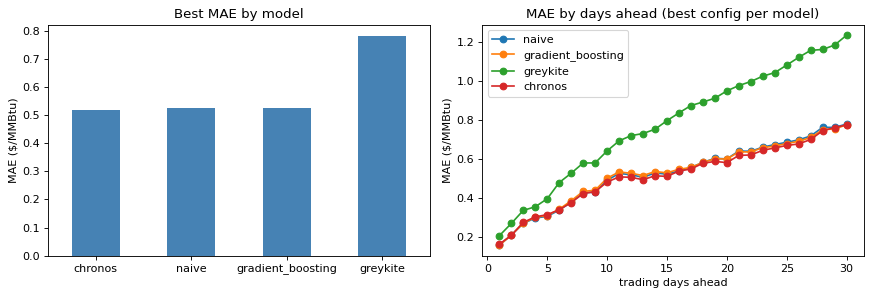

In [7]:
by_step = pd.DataFrame({name: report.metrics_by_step()["mae"] for name, report in best.items()})

figure, (left, right) = plt.subplots(1, 2, figsize=(11, 3.8), dpi=80)
best_table["mae"].astype(float).plot.bar(ax=left, color="steelblue")
left.set_title("Best MAE by model")
left.set_ylabel("MAE ($/MMBtu)")
left.tick_params(axis="x", rotation=0)
by_step.plot(ax=right, marker="o")
right.set_title("MAE by days ahead (best config per model)")
right.set_xlabel("trading days ahead")
right.set_ylabel("MAE ($/MMBtu)")
figure.tight_layout()
plt.show()

## Error by horizon bucket

Best config per model, scored on days 1 to 5, 6 to 15, and 16 to 30 ahead.

In [8]:
buckets = pd.concat({name: report.metrics_by_bucket() for name, report in best.items()})
buckets.round(4)

mae    rmse     mape     wape    bias
                  days_ahead                                             
naive             days 1 to 5    0.2476  0.3849   6.1753   6.5001 -0.0015
                  days 6 to 15   0.4656  0.6852  11.9472  12.2125 -0.0047
                  days 16 to 30  0.6589  0.9757  16.9683  17.3540  0.0110
gradient_boosting days 1 to 5    0.2494  0.3908   6.2016   6.5457 -0.0030
                  days 6 to 15   0.4734  0.7012  11.9902  12.4170 -0.0156
                  days 16 to 30  0.6550  0.9718  16.8071  17.2505  0.0041
greykite          days 1 to 5    0.3120  0.4522   8.1161   8.1912  0.0053
                  days 6 to 15   0.6487  0.8916  17.2638  17.0130 -0.0181
                  days 16 to 30  1.0277  1.3711  27.1460  27.0673 -0.0240
chronos           days 1 to 5    0.2524  0.3997   6.2302   6.6247 -0.0204
                  days 6 to 15   0.4577  0.6670  11.6199  12.0042 -0.0312
                  days 16 to 30  0.6455  0.9486  16.4076  17.0012 -0.0344

## Best config

The publishing rule only picks a model over naive when it lowers error by at least the margin in `tuning.yaml`.

In [9]:
publisher = ModelPublisher(
    provider,
    tuning.registered_model_name,
    tuning.model_alias,
    tuning.selection_metric,
    tuning.min_improvement,
)
decision = publisher.choose(optimizer.reports)
print(decision.reason)
print("model to publish:", decision.report.model_name, decision.report.config.to_json())

chronos beat naive by 1.63%
model to publish: chronos {"context_length": 640, "device": "cpu", "model_id": "amazon/chronos-2", "use_weather": true, "use_weekend": false, "use_yearly": false, "weather_columns": ["hdd", "cdd"], "weekly_harmonics": 0}


The grid search notebook publishes the official model. This notebook only reports what Bayesian search would pick.